# Step 7: Extending the project (forecasting, classification, clustering, hypothesis test)

Steps 1-6 predict a battery's capacity, SOH and RUL from **one discharge cycle**. This notebook asks four new questions on the same `all_batteries.csv`:

| Part | Question | Technique |
|---|---|---|
| **A. Time series forecasting** | Can we forecast the capacity curve *forward* from a battery's history? | Naive, linear trend, Holt (damped), ARIMA with rolling-origin backtesting |
| **B. Classification** | Is a cycle **healthy** (SOH >= 80%) or **degraded** (SOH < 80%)? | Logistic Regression, Random Forest, XGBoost |
| **C. Clustering** | Do cycles fall into natural groups without using any labels? | K-Means, silhouette score, PCA |
| **D. Hypothesis test** | Do degraded cycles really run hotter (and differ in other features)? | Welch t-test, Mann-Whitney, effect size, multiple-testing correction |

**Same honest rules as the earlier steps.** Models are always tested on a battery they have not seen (leave-one-battery-out), and forecasts are always scored on cycles that come *after* the data used to fit them. Random row splits would leak answers because neighbouring cycles are nearly identical.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

df = pd.read_csv("all_batteries.csv")
FEATURES = ["avg_voltage", "min_voltage", "avg_current", "avg_temp", "max_temp", "discharge_time_s"]
BATTERIES = sorted(df["battery"].unique())
EOL_SOH = 80                                   # end-of-life line used in the whole project
df["degraded"] = (df["soh_percent"] < EOL_SOH).astype(int)

Path("images").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

# plot style: thin lines, quiet grid, colour-blind-safe hues used in a fixed order
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e3e2de"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "font.size": 10,
})

print(df.shape, "| batteries:", BATTERIES)
print("Share of degraded cycles (SOH < 80%%): %.1f%%" % (100 * df["degraded"].mean()))
df.groupby("battery").agg(cycles=("cycle", "count"), start_capacity_Ah=("capacity_ah", "first"),
                          degraded_cycles=("degraded", "sum")).round(2)

(636, 11) | batteries: ['B0005', 'B0006', 'B0007', 'B0018']
Share of degraded cycles (SOH < 80%): 43.6%


,cycles,start_capacity_Ah,degraded_cycles
battery,,,
B0005,168,1.86,66
B0006,168,2.04,108
B0007,168,1.89,45
B0018,132,1.86,58


---
## A. Time series forecasting

**Idea.** A battery's capacity over cycles is a *time series*, like a daily stock price or monthly sales. Steps 3-5 predicted each cycle on its own. Here we use the **history** to forecast the **future**.

**First check: is the series "stationary"?** Many forecasting models assume the series does not drift. The Augmented Dickey-Fuller (ADF) test checks this (p < 0.05 means stationary). Battery capacity keeps falling, so we expect it to fail, and the standard fix is to model the *cycle-to-cycle change* instead (called differencing, the "I" in ARIMA).

In [2]:
from statsmodels.tsa.stattools import adfuller

rows = []
for b in BATTERIES:
    y = df.loc[df["battery"] == b, "capacity_ah"].values
    rows.append({"battery": b,
                 "ADF p-value, capacity": "%.2f" % adfuller(y)[1],
                 "ADF p-value, cycle-to-cycle change": "%.1e" % adfuller(np.diff(y))[1]})
pd.DataFrame(rows)

,battery,"ADF p-value, capacity","ADF p-value, cycle-to-cycle change"
0,B0005,0.89,1.7e-19
1,B0006,0.60,4.0e-16
2,B0007,0.86,5.8e-20
3,B0018,0.57,5.4e-13


**Models compared** (all predict capacity, scored in *SOH points*: error in Ah divided by the battery's first-cycle capacity x 100, the same unit as the earlier steps):

| Model | In plain words |
|---|---|
| **Naive** | "Capacity stays where it is now." The baseline every real model must beat. |
| **Linear trend** | Draw a straight line through the last 30 cycles and keep going. |
| **Holt (damped)** | Smoothing that tracks level and slope, with the slope slowly flattening out. |
| **ARIMA(1,1,0) + drift** | Models the cycle-to-cycle change with a steady average decline (drift). |

**How it is scored: rolling-origin backtest.** Like replaying history: stand at cycle 40, forecast the next 20 cycles, score against what really happened; move to cycle 50, repeat; and so on, for each battery. This gives 41 forecasts instead of one lucky or unlucky split.

In [3]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tools.sm_exceptions import ConvergenceWarning

MODELS = ["Naive", "Linear trend (last 30)", "Holt (damped)", "ARIMA(1,1,0) + drift"]
arima_fits, arima_not_converged = 0, 0

def forecast(model, y, h):
    # Forecast the next h values of series y with the named model.
    global arima_fits, arima_not_converged
    if model == "Naive":
        return np.repeat(y[-1], h)
    if model == "Linear trend (last 30)":
        k = 30
        slope_intercept = np.polyfit(np.arange(k), y[-k:], 1)
        return np.polyval(slope_intercept, np.arange(k, k + h))
    if model == "Holt (damped)":
        fit = ExponentialSmoothing(y, trend="add", damped_trend=True,
                                   initialization_method="estimated").fit()
        return fit.forecast(h)
    if model == "ARIMA(1,1,0) + drift":
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fit = ARIMA(y, order=(1, 1, 0), trend="t").fit()
        arima_fits += 1
        arima_not_converged += any(issubclass(w.category, ConvergenceWarning) for w in caught)
        return fit.forecast(h)

HORIZON, FIRST_ORIGIN, STEP = 20, 40, 10
records = []
for b in BATTERIES:
    y = df.loc[df["battery"] == b, "capacity_ah"].values
    start_cap = y[0]
    for origin in range(FIRST_ORIGIN, len(y) - HORIZON + 1, STEP):
        actual = y[origin:origin + HORIZON]
        for m in MODELS:
            err = (forecast(m, y[:origin], HORIZON) - actual) / start_cap * 100   # SOH points
            records.append({"battery": b, "origin_cycle": origin, "model": m,
                            "MAE": np.abs(err).mean(), "bias": err.mean()})
bt = pd.DataFrame(records)

summary = bt.groupby("model")[["MAE", "bias"]].mean().loc[MODELS]
naive_mae = summary.loc["Naive", "MAE"]
summary["MAE vs naive"] = (1 - summary["MAE"] / naive_mae).map("{:.0%}".format)
summary = summary.rename(columns={"MAE": "MAE (SOH pts)", "bias": "bias (SOH pts)"}).round(2)
print("%d forecasts per model | ARIMA fits that did not fully converge: %d of %d"
      % (bt["model"].value_counts().iloc[0], arima_not_converged, arima_fits))
bt.to_csv("results/ts_backtest_all.csv", index=False)
summary.to_csv("results/ts_backtest_summary.csv")
summary

41 forecasts per model | ARIMA fits that did not fully converge: 2 of 41


,MAE (SOH pts),bias (SOH pts),MAE vs naive
model,,,
Naive,2.72,2.52,0%
Linear trend (last 30),1.70,-0.13,38%
Holt (damped),1.71,0.91,37%
"ARIMA(1,1,0) + drift",1.66,0.23,39%


In [4]:
# MAE per battery (SOH points, 20 cycles ahead)
bt.pivot_table(index="battery", columns="model", values="MAE")[MODELS].round(2)

model,Naive,Linear trend (last 30),Holt (damped),"ARIMA(1,1,0) + drift"
battery,,,,
B0005,2.79,1.35,1.68,1.45
B0006,3.22,1.94,1.90,1.99
B0007,2.39,1.08,1.43,1.29
B0018,2.42,2.71,1.89,2.00


**Reading the backtest**

- Every real model beats "nothing changes": the best forecast errors are about **1.7 SOH points** against **2.7** for naive (roughly 35-40% lower). The naive forecast is also biased high (+2.5 points), because it ignores that the battery keeps declining.
- ARIMA, Holt and the linear trend are **too close to call** (1.66 / 1.71 / 1.70). With 41 forecasts from four batteries I would not claim one is better.
- No single model wins everywhere: the linear trend is best on B0005 and B0007 but the worst of the three on B0018.

Next, a picture of one forecast from the middle of each battery's life. The sudden upward jumps in the real curves are usually attributed to rest periods between tests, which let a battery recover some capacity. None of these models can predict them, which adds noise to every forecast.

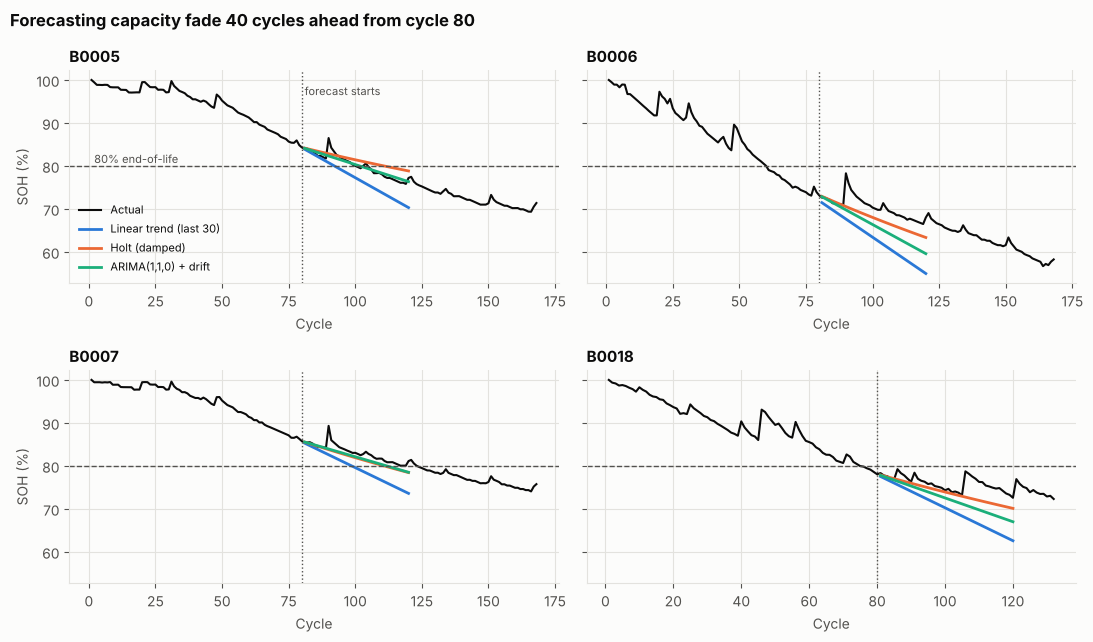

In [5]:
ORIGIN, LONG_H = 80, 40
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharey=True)
for ax, b in zip(axes.ravel(), BATTERIES):
    d = df[df["battery"] == b].reset_index(drop=True)
    y, c0 = d["capacity_ah"].values, d["capacity_ah"].iloc[0]
    soh = y / c0 * 100
    ax.plot(d["cycle"], soh, color=INK, lw=1.5, label="Actual")
    for m, col in [("Linear trend (last 30)", BLUE), ("Holt (damped)", ORANGE), ("ARIMA(1,1,0) + drift", AQUA)]:
        f = forecast(m, y[:ORIGIN], LONG_H) / c0 * 100
        ax.plot(d["cycle"].iloc[ORIGIN:ORIGIN + LONG_H], f, color=col, lw=2, label=m)
    ax.axvline(ORIGIN, color=MUTED, lw=1, ls=":")
    ax.axhline(EOL_SOH, color=MUTED, lw=1, ls="--")
    ax.set_title(b)
    ax.set_xlabel("Cycle")
axes[0, 0].set_ylabel("SOH (%)"); axes[1, 0].set_ylabel("SOH (%)")
axes[0, 0].text(ORIGIN + 1, 99, "forecast starts", color=MUTED, fontsize=8, va="top")
axes[0, 0].text(2, EOL_SOH + 0.7, "80% end-of-life", color=MUTED, fontsize=8)
axes[0, 0].legend(loc="lower left", fontsize=8)
fig.suptitle("Forecasting capacity fade 40 cycles ahead from cycle 80", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("images/ts_forecast.png", dpi=150)
plt.show()

**Forecasting the end of life.** The question that matters for an EV: *"from an early checkup, when will this battery hit 80% SOH?"* Standing at **cycle 50** (every battery is still above 80% there), extrapolate until the forecast crosses 80%.

In [6]:
ORIGIN_EOL, MAX_H = 50, 200
rows = []
for b in BATTERIES:
    d = df[df["battery"] == b].reset_index(drop=True)
    y, c0 = d["capacity_ah"].values, d["capacity_ah"].iloc[0]
    actual_eol = int(d.loc[d["soh_percent"] < EOL_SOH, "cycle"].iloc[0])
    row = {"battery": b, "actual EOL cycle": actual_eol}
    for m in MODELS[1:]:
        soh_f = forecast(m, y[:ORIGIN_EOL], MAX_H) / c0 * 100
        hit = np.where(soh_f < EOL_SOH)[0]
        row[m] = ORIGIN_EOL + 1 + int(hit[0]) if len(hit) else np.nan   # NaN = never crosses 80%
    rows.append(row)
eol = pd.DataFrame(rows).set_index("battery")
eol.to_csv("results/ts_eol_forecast.csv")

err = eol[MODELS[1:]].sub(eol["actual EOL cycle"], axis=0)
print("Mean absolute error in cycles (forecast crossing - actual crossing):")
print(err.abs().mean().round(1).to_string())
print("\nForecast end-of-life cycle (NaN = forecast never reaches 80%):")
eol

Mean absolute error in cycles (forecast crossing - actual crossing):
Linear trend (last 30)    22.5
Holt (damped)              NaN
ARIMA(1,1,0) + drift      57.8

Forecast end-of-life cycle (NaN = forecast never reaches 80%):


,actual EOL cycle,Linear trend (last 30),Holt (damped),"ARIMA(1,1,0) + drift"
battery,,,,
B0005,101,140,NaN,209
B0006,61,64,NaN,79
B0007,124,137,NaN,208
B0018,75,110,NaN,96


**Reading the end-of-life forecast.** This is the weakest result, and worth stating plainly:

- Every forecast that crosses 80% is **too optimistic** (it predicts a later end of life than the real one). The linear trend is off by about 22 cycles on average and ARIMA by about 58.
- The damped Holt model **never reaches 80%**, because its slope flattens out.
- Why: the first 50 cycles fade slowly and the fade **speeds up later**, so a straight-line extrapolation from early life overestimates how long the battery lasts. This matches the Step 5 finding that RUL is hard early in life.

So forecasting works for *short-term* capacity (20 cycles ahead), but a long-range end-of-life call from early data needs a model of the accelerating decline, which is a natural next step.

---
## B. Classification: healthy vs degraded

**Idea.** Instead of a number (SOH), predict a **label**: `degraded = 1` if SOH < 80% (the end-of-life line), else `0`. This is the yes/no question a maintenance system actually asks.

- **Evaluation:** leave-one-battery-out, the same as Step 3b. Train on three batteries, test on the fourth, repeat four times, and average.
- **Baseline:** always predict the majority class ("healthy").
- **Metrics:** with a safety question, a missed degraded battery (false negative) costs more than a false alarm, so **recall** matters as much as accuracy. *Precision* = of the cycles flagged degraded, how many really are. *Recall* = of the truly degraded cycles, how many we caught. *F1* balances the two.
- **Ablation:** the README notes that `discharge_time_s` is almost the same information as capacity and a real vehicle rarely completes a full discharge. So each model is also tested **without** it.

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from xgboost import XGBClassifier

NO_DT = [f for f in FEATURES if f != "discharge_time_s"]

def make_model(name):
    if name == "Majority baseline":
        return DummyClassifier(strategy="most_frequent")
    if name.startswith("Logistic Regression"):
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42)
    if name.startswith("XGBoost"):
        return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                             random_state=42, eval_metric="logloss")

EXPERIMENTS = [("Majority baseline", FEATURES), ("Logistic Regression", FEATURES),
               ("Random Forest", FEATURES), ("XGBoost", FEATURES),
               ("Logistic Regression (no discharge_time)", NO_DT),
               ("XGBoost (no discharge_time)", NO_DT)]

fold_rows, oof_pred = [], {}
for name, feats in EXPERIMENTS:
    pred = np.zeros(len(df), dtype=int)
    for held_out in BATTERIES:
        train, test = df["battery"] != held_out, df["battery"] == held_out
        model = make_model(name).fit(df.loc[train, feats], df.loc[train, "degraded"])
        pred[test] = model.predict(df.loc[test, feats])
        proba = model.predict_proba(df.loc[test, feats])[:, 1]
        y_true = df.loc[test, "degraded"]
        fold_rows.append({"model": name, "held_out": held_out,
                          "accuracy": accuracy_score(y_true, pred[test]),
                          "precision": precision_score(y_true, pred[test], zero_division=0),
                          "recall": recall_score(y_true, pred[test]),
                          "F1": f1_score(y_true, pred[test]),
                          "ROC-AUC": 0.5 if name == "Majority baseline" else roc_auc_score(y_true, proba)})
    oof_pred[name] = pred

folds = pd.DataFrame(fold_rows)
cls = folds.groupby("model", sort=False)[["accuracy", "precision", "recall", "F1", "ROC-AUC"]].mean().round(3)
folds.to_csv("results/classification_folds.csv", index=False)
cls.to_csv("results/classification_results.csv")
cls

,accuracy,precision,recall,F1,ROC-AUC
model,,,,,
Majority baseline,0.564,0.000,0.000,0.000,0.500
Logistic Regression,0.914,0.823,0.993,0.893,0.997
Random Forest,0.900,0.921,0.863,0.877,0.997
XGBoost,0.887,0.970,0.800,0.865,0.996
Logistic Regression (no discharge_time),0.957,0.982,0.895,0.932,0.998
XGBoost (no discharge_time),0.875,0.739,0.626,0.673,0.996


In [8]:
# F1 for each held-out battery: how stable is each model?
folds.pivot_table(index="model", columns="held_out", values="F1", sort=False).round(2)

held_out,B0005,B0006,B0007,B0018
model,,,,
Majority baseline,0.00,0.00,0.00,0.00
Logistic Regression,0.90,0.99,0.77,0.91
Random Forest,0.83,0.85,0.86,0.97
XGBoost,0.83,0.77,0.93,0.94
Logistic Regression (no discharge_time),0.97,0.98,0.83,0.95
XGBoost (no discharge_time),0.83,0.98,0.00,0.88


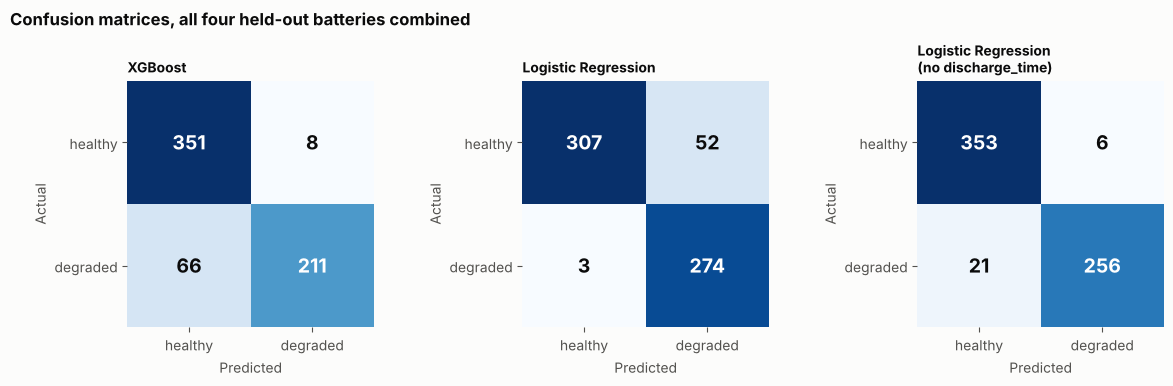

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, name in zip(axes, ["XGBoost", "Logistic Regression", "Logistic Regression (no discharge_time)"]):
    cm = confusion_matrix(df["degraded"], oof_pred[name])
    ax.imshow(cm, cmap="Blues")
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, fontweight="bold",
                    color="white" if cm[i, j] > cm.max() / 2 else INK)
    ax.set_xticks([0, 1], ["healthy", "degraded"]); ax.set_yticks([0, 1], ["healthy", "degraded"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(name.replace(" (no discharge_time)", "\n(no discharge_time)"), fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("Confusion matrices, all four held-out batteries combined", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("images/classification_confusion.png", dpi=150)
plt.show()

**Reading the classification results**

- Every model beats the majority baseline (56% accuracy) by a wide margin.
- **ROC-AUC is about 0.996-0.998 for all real models.** The models rank cycles almost perfectly by "how degraded", so the signal is there. The weaker accuracy / F1 comes from the **fixed 0.5 cut-off not transferring to an unseen battery**, because each battery's 80% line is relative to its own starting capacity.
- **Logistic Regression catches the most** (recall 0.99) but raises false alarms (precision 0.82). **XGBoost is the reverse**: precision 0.97 but recall only 0.80, so it **misses about a quarter of degraded cycles** in the pooled confusion matrix. For a safety check, missed cycles are the costly error.
- **Results swing with the held-out battery** (the F1 table). Dropping `discharge_time_s` makes Logistic Regression *better* but makes XGBoost collapse on B0007 (F1 = 0.00). With only four folds, treat model rankings as indicative, not final, and avoid over-reading small F1 gaps.

**Takeaway.** The simple, transparent model is a good candidate here, and it works even without the full-discharge feature. A real system would also tune the decision threshold on more batteries.

---
## C. Clustering: do cycles group naturally?

**Idea.** Clustering has **no labels**. Think of sorting a pile of photos into piles without being told the categories. K-Means groups cycles that look alike across the six measurements (after scaling so no feature dominates). Then we check afterwards whether the groups mean anything.

**Choosing the number of clusters (k).** The *elbow* (inertia) and the *silhouette score* (higher = tighter, better-separated groups) help, but both can be ambiguous.

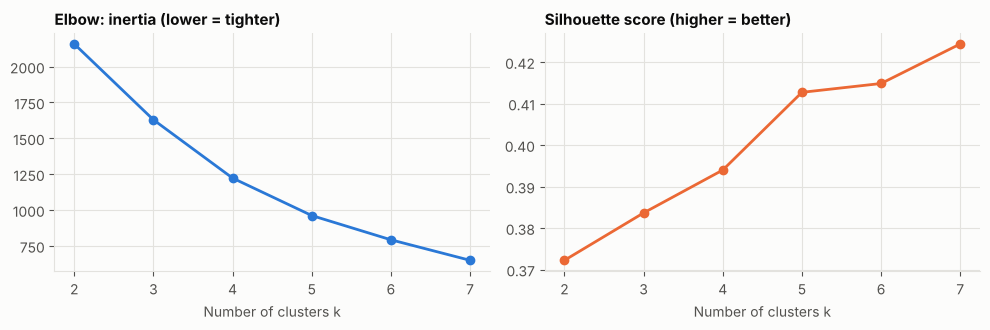

k,2,3,4,5,6,7
inertia,2158.000,1629.000,1222.000,961.000,792.000,649.000
silhouette,0.372,0.384,0.394,0.413,0.415,0.424


In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(df[FEATURES])

ks = list(range(2, 8))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(ks, inertia, marker="o", color=BLUE); axes[0].set_title("Elbow: inertia (lower = tighter)")
axes[1].plot(ks, sil, marker="o", color=ORANGE);   axes[1].set_title("Silhouette score (higher = better)")
for ax in axes: ax.set_xlabel("Number of clusters k")
fig.tight_layout(); plt.show()
pd.DataFrame({"k": ks, "inertia": np.round(inertia, 0), "silhouette": np.round(sil, 3)}).set_index("k").T

There is **no clear elbow and no peak**: the silhouette score just keeps creeping up from 0.37 to 0.42 as k grows. In other words the data has no obvious natural number of groups. I use **k = 3** because it is easy to read (roughly early / middle / late), and I treat it as a description, not a discovery.

In [11]:
km = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X)
# number clusters 1..3 from highest to lowest average SOH, so the labels are easy to read
order = df.assign(c=km.labels_).groupby("c")["soh_percent"].mean().sort_values(ascending=False).index
df["cluster"] = [list(order).index(c) + 1 for c in km.labels_]

profile = df.groupby("cluster").agg(cycles=("cycle", "size"), mean_cycle_number=("cycle", "mean"),
                                    mean_SOH=("soh_percent", "mean"), share_degraded=("degraded", "mean")).round(2)
profile.to_csv("results/clustering_profile.csv")
print(profile.to_string())
print("\nCycles per cluster and battery:")
print(pd.crosstab(df["cluster"], df["battery"]).to_string())
print("\nAgreement with known labels (Adjusted Rand Index: 0 = random, 1 = identical):")
print("  clusters vs battery identity : %.2f" % adjusted_rand_score(df["battery"], df["cluster"]))
print("  clusters vs healthy/degraded : %.2f" % adjusted_rand_score(df["degraded"], df["cluster"]))

         cycles  mean_cycle_number  mean_SOH  share_degraded
cluster                                                     
1           284              48.47     89.22            0.19
2           154              89.14     86.00            0.29
3           198             120.57     71.26            0.90

Cycles per cluster and battery:
battery  B0005  B0006  B0007  B0018
cluster                            
1           82     63     16    123
2            1      1    152      0
3           85    104      0      9

Agreement with known labels (Adjusted Rand Index: 0 = random, 1 = identical):
  clusters vs battery identity : 0.36
  clusters vs healthy/degraded : 0.29


PCA keeps 80% of the variance in 2 components


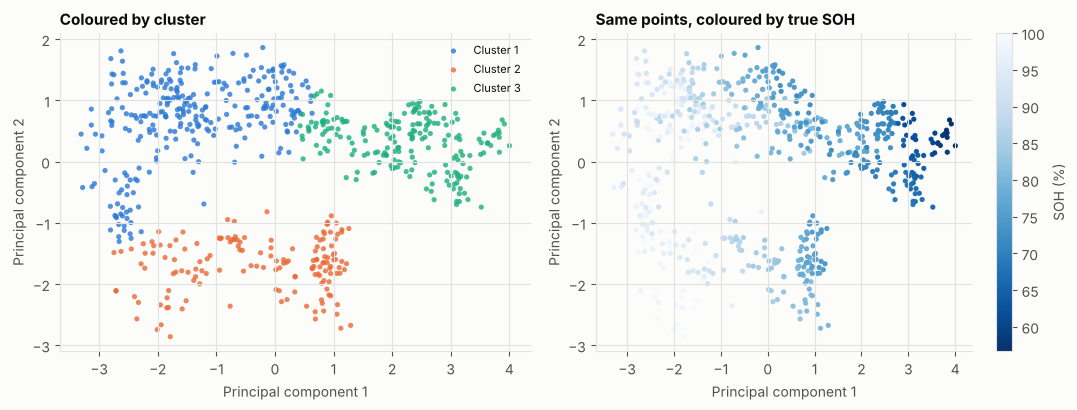

In [12]:
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
print("PCA keeps %.0f%% of the variance in 2 components" % (100 * pca.explained_variance_ratio_.sum()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for c, col in zip([1, 2, 3], [BLUE, ORANGE, AQUA]):
    m = (df["cluster"] == c).values
    axes[0].scatter(P[m, 0], P[m, 1], s=14, color=col, alpha=0.8, label="Cluster %d" % c, edgecolors="none")
axes[0].set_title("Coloured by cluster"); axes[0].legend(fontsize=8)
sc = axes[1].scatter(P[:, 0], P[:, 1], s=14, c=df["soh_percent"], cmap="Blues_r", edgecolors="none")
axes[1].set_title("Same points, coloured by true SOH")
fig.colorbar(sc, ax=axes[1], label="SOH (%)")
for ax in axes:
    ax.set_xlabel("Principal component 1"); ax.set_ylabel("Principal component 2")
fig.tight_layout()
fig.savefig("images/clustering_pca.png", dpi=150)
plt.show()

**What the clusters turn out to be.** Cluster 1 holds mostly early, healthy cycles and cluster 3 mostly late, degraded ones (about 90% of its cycles are below 80% SOH). But the clusters also **split by battery**: B0007 sits almost entirely in one cluster, and the agreement with *battery identity* (0.36) is as strong as with *healthy/degraded* (0.29). The raw measurements differ more between batteries than between young and old cycles.

**Test of that explanation.** If battery-to-battery differences are hiding the ageing signal, comparing each cycle with *its own battery's* average should reveal it. So I re-scale the features **within each battery** and cluster again.

In [13]:
X_within = df.groupby("battery")[FEATURES].transform(lambda c: (c - c.mean()) / c.std()).values

rows = []
for k in (2, 3, 4):
    labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_within).labels_
    rows.append({"k": k, "silhouette": silhouette_score(X_within, labels),
                 "ARI vs battery": adjusted_rand_score(df["battery"], labels),
                 "ARI vs healthy/degraded": adjusted_rand_score(df["degraded"], labels)})
within = pd.DataFrame(rows).set_index("k").round(2)
within.to_csv("results/clustering_within_battery.csv")
within

,silhouette,ARI vs battery,ARI vs healthy/degraded
k,,,
2,0.49,-0.0,0.52
3,0.36,0.0,0.41
4,0.37,0.0,0.35


**Reading it.** After removing each battery's own baseline, the clusters stop tracking battery identity (agreement about 0) and match healthy/degraded better (0.52 at k = 2, with a higher silhouette of 0.49). So the ageing pattern is real, but it is **relative to each battery's own starting point**. For a real vehicle that suggests comparing each pack against its **own early-life baseline** instead of a fleet-wide average.

*Caveat:* here the baseline uses each battery's whole history, including later cycles. A live system would only have the early cycles to build it from.

---
## D. Hypothesis testing: do degraded cycles run hotter?

**Question.** An aged battery has higher internal resistance, which should show up as extra heat (an I²R effect, familiar from electrical engineering). So:

- **H0:** the mean battery temperature is the **same** in healthy (SOH >= 80%) and degraded (SOH < 80%) cycles.
- **H1:** the means **differ**. (Two-sided test, so I am not assuming the direction.)
- Significance level: 0.05.

I test all six features, not just temperature, so I am not cherry-picking, and I correct for running six tests at once (Bonferroni: multiply each p-value by 6).

**Which tests**

| Test | Why |
|---|---|
| **Welch t-test** | Compares two means without assuming equal variances |
| **Mann-Whitney U** | Checks the t-test result without assuming a normal distribution |
| **Cohen's d** | The size of the difference, in standard deviations (about 0.2 small, 0.5 medium, 0.8 large). A p-value alone says nothing about size. |
| **Battery-level paired t-test** | Cycles from one battery are **not independent** (neighbouring cycles are nearly identical), which makes cycle-level p-values far too small. So I also average each battery's healthy and degraded cycles and compare the **four pairs**. This is the more conservative test, but with n = 4 it has little power. |

In [14]:
def fmt_p(p):
    return "%.1e" % p if p < 0.001 else "%.3f" % p

rows = []
for f in FEATURES:
    healthy = df.loc[df["degraded"] == 0, f]
    degraded = df.loc[df["degraded"] == 1, f]
    t, p_welch = stats.ttest_ind(healthy, degraded, equal_var=False)
    _, p_mw = stats.mannwhitneyu(healthy, degraded)
    pooled_sd = np.sqrt((healthy.var(ddof=1) + degraded.var(ddof=1)) / 2)
    per_batt = df.groupby(["battery", "degraded"])[f].mean().unstack()          # 4 rows: healthy vs degraded
    _, p_pair = stats.ttest_rel(per_batt[0], per_batt[1])
    rows.append({"feature": f, "healthy mean": healthy.mean(), "degraded mean": degraded.mean(),
                 "Cohen's d": (degraded.mean() - healthy.mean()) / pooled_sd,
                 "Welch p (cycles)": p_welch, "Mann-Whitney p": p_mw,
                 "paired p (4 batteries)": p_pair,
                 "batteries where degraded > healthy": int((per_batt[1] > per_batt[0]).sum())})
tests = pd.DataFrame(rows).set_index("feature")
tests["Welch p x6"] = (tests["Welch p (cycles)"] * 6).clip(upper=1)
tests["paired p x6"] = (tests["paired p (4 batteries)"] * 6).clip(upper=1)
tests.to_csv("results/hypothesis_tests.csv")

show = tests.copy()
for c in ["healthy mean", "degraded mean", "Cohen's d"]:
    show[c] = show[c].round(2)
for c in ["Welch p (cycles)", "Mann-Whitney p", "paired p (4 batteries)", "Welch p x6", "paired p x6"]:
    show[c] = show[c].map(fmt_p)
show[["healthy mean", "degraded mean", "Cohen's d", "Welch p (cycles)", "Welch p x6", "Mann-Whitney p",
      "paired p (4 batteries)", "paired p x6", "batteries where degraded > healthy"]]

,healthy mean,degraded mean,Cohen's d,Welch p (cycles),Welch p x6,Mann-Whitney p,paired p (4 batteries),paired p x6,batteries where degraded > healthy
feature,,,,,,,,,
avg_voltage,3.53,3.45,-3.00,2.5e-151,1.5e-150,7.0e-101,0.015,0.091,0
min_voltage,2.35,2.43,0.37,3.9e-06,2.4e-05,6.1e-05,0.132,0.791,3
avg_current,-1.90,-1.75,2.26,6.4e-100,3.8e-99,8.0e-86,0.054,0.321,4
avg_temp,31.93,32.84,1.03,1.1e-32,6.8e-32,6.6e-33,0.089,0.531,4
max_temp,39.01,40.30,1.02,1.5e-33,8.8e-33,2.1e-30,0.042,0.255,4
discharge_time_s,3280.15,2905.50,-2.49,7.8e-132,4.7e-131,2.8e-89,7.3e-05,4.4e-04,0


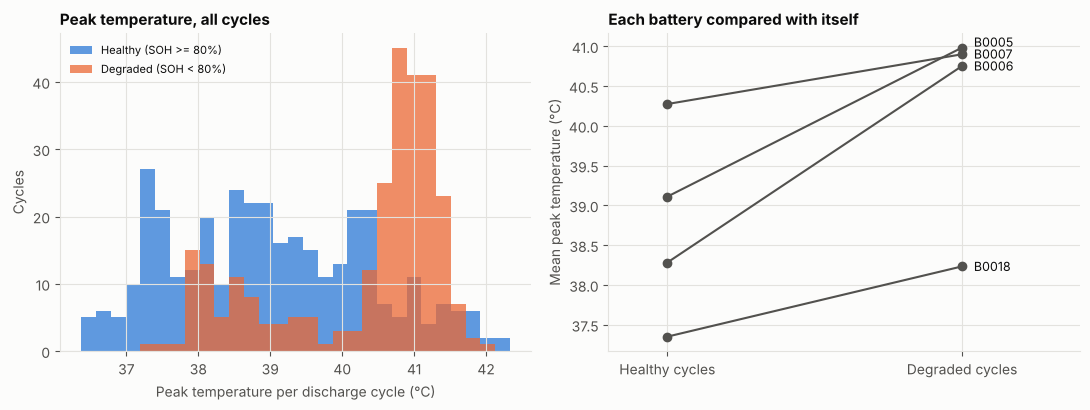

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

bins = np.linspace(df["max_temp"].min(), df["max_temp"].max(), 30)
axes[0].hist(df.loc[df["degraded"] == 0, "max_temp"], bins=bins, color=BLUE, alpha=0.75, label="Healthy (SOH >= 80%)")
axes[0].hist(df.loc[df["degraded"] == 1, "max_temp"], bins=bins, color=ORANGE, alpha=0.75, label="Degraded (SOH < 80%)")
axes[0].set_xlabel("Peak temperature per discharge cycle (°C)"); axes[0].set_ylabel("Cycles")
axes[0].set_title("Peak temperature, all cycles"); axes[0].legend(fontsize=8)

means = df.groupby(["battery", "degraded"])["max_temp"].mean().unstack()
label_y, last = {}, None          # nudge end labels apart so close lines do not collide
for b in sorted(BATTERIES, key=lambda b: means.loc[b, 1]):
    label_y[b] = means.loc[b, 1] if last is None else max(means.loc[b, 1], last + 0.15)
    last = label_y[b]
for b in BATTERIES:
    axes[1].plot([0, 1], means.loc[b], marker="o", color=MUTED, lw=1.5)
    axes[1].text(1.04, label_y[b], b, va="center", fontsize=9, color=INK)
axes[1].set_xticks([0, 1], ["Healthy cycles", "Degraded cycles"]); axes[1].set_xlim(-0.2, 1.4)
axes[1].set_ylabel("Mean peak temperature (°C)"); axes[1].set_title("Each battery compared with itself")
fig.tight_layout()
fig.savefig("images/hypothesis_max_temp.png", dpi=150)
plt.show()

**Reading the tests**

- **Cycle level:** all six features differ between healthy and degraded cycles, with tiny p-values that survive the correction, and Mann-Whitney agrees. The effects are large: Cohen's d is about -3.0 for average voltage, -2.5 for discharge time, +2.3 for average current, and about **+1.0 for temperature** (peak temperature 39.0 °C healthy vs 40.3 °C degraded). **But** these p-values are inflated because the cycles are not independent.
- **Battery level (the stricter view):** only **discharge time** stays significant after correcting for six tests (a shorter discharge is just a lower capacity, so this is nearly built into the SOH definition). Average voltage (p = 0.015) and peak temperature (p = 0.042) pass 0.05 *before* correction but not after.
- **Temperature direction is consistent:** degraded cycles ran hotter in **all 4 of 4 batteries**, which fits the higher-resistance explanation. With four batteries that is encouraging, **not proof**.

**Conclusion.** I reject H0 at the cycle level, but I would only claim that degraded cycles *tend* to run about 1 °C hotter, with the direction consistent across batteries. Confirming it statistically needs more batteries.

---
## Summary

| Part | Headline result | Main caveat |
|---|---|---|
| **A. Forecasting** | Best models forecast capacity 20 cycles ahead to about 1.7 SOH points, roughly 35-40% better than "no change". | ARIMA, Holt and linear are indistinguishable. Forecasting end of life from cycle 50 is too optimistic (linear about 22 cycles off, ARIMA about 58, Holt never reaches 80%). |
| **B. Classification** | Healthy vs degraded: F1 about 0.87-0.93 for the four main models on unseen batteries, ROC-AUC about 0.997, well above the 56% baseline. | Fixed cut-off transfers imperfectly. XGBoost misses about a quarter of degraded cycles, and results swing by held-out battery. |
| **C. Clustering** | No natural k. Raw clusters mix battery identity with ageing. Per-battery scaling recovers healthy/degraded (ARI 0.52). | Baseline here uses each battery's full history. |
| **D. Hypothesis test** | Degraded cycles run about 1.3 °C hotter at peak (d about 1.0), in 4 of 4 batteries. | Cycles are not independent. At battery level (n = 4) only discharge time survives correction. |

**Limits shared by all four parts:** four batteries from one lab, lab conditions rather than real driving, and `discharge_time_s` is nearly the same information as capacity. Everything here is a proof of concept.